In [7]:
import pandas as pd
import psycopg

# Replace these values with your PostgreSQL connection details
DB_CONFIG = {
    "host": "localhost",
    "port": 5432,
    "dbname": "customer_marketing_analytics",
    "user": "postgres",
    "password": "raed20012"
}

with psycopg.connect(**DB_CONFIG) as conn:
    segments = pd.read_sql(
        """
        SELECT
            customer_id,
            recency_days,
            frequency,
            monetary,
            r_score,
            f_score,
            m_score,
            customer_segment
        FROM public.customer_rfm
        """,
        conn
    )

print("Customers loaded:", len(segments))
display(segments.head())

Customers loaded: 4338


C:\Users\raedh\AppData\Local\Temp\ipykernel_4228\1059104130.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  segments = pd.read_sql(


,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score,customer_segment
0,16048,374,2,256.44,1,3,2,At Risk
1,13747,374,1,79.60,1,1,1,Hibernating
2,14142,374,1,311.81,1,2,2,Hibernating
3,13065,374,1,205.86,1,1,1,Hibernating
4,15350,374,1,115.65,1,1,1,Hibernating


In [8]:
summary = (
    segments.groupby("customer_segment")
    .agg(
        customers=("customer_id", "nunique"),
        avg_recency_days=("recency_days", "mean"),
        avg_orders=("frequency", "mean"),
        avg_spend=("monetary", "mean"),
        total_revenue=("monetary", "sum")
    )
    .sort_values("total_revenue", ascending=False)
    .round(2)
)

display(summary)

,customers,avg_recency_days,avg_orders,avg_spend,total_revenue
customer_segment,,,,,
Champions,947,12.88,11.16,6051.11,5730402.80
Loyal Customers,487,37.87,5.22,1922.97,936486.59
At Risk,670,150.74,3.39,1268.33,849783.34
Needs Attention,856,39.76,1.86,686.47,587616.28
Hibernating,1066,217.89,1.09,464.85,495535.20
Recent Customers,312,18.39,1.25,921.10,287384.68


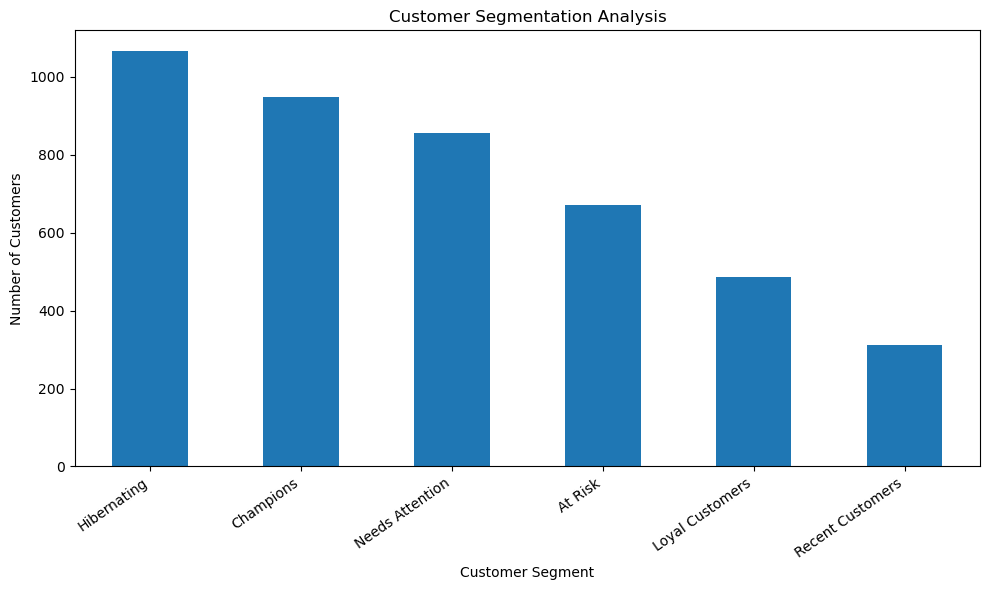

In [9]:
import matplotlib.pyplot as plt

# Count customers in each segment
segment_counts = (
    segments["customer_segment"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig("customer_segments.png", dpi=300, bbox_inches="tight")
plt.show()

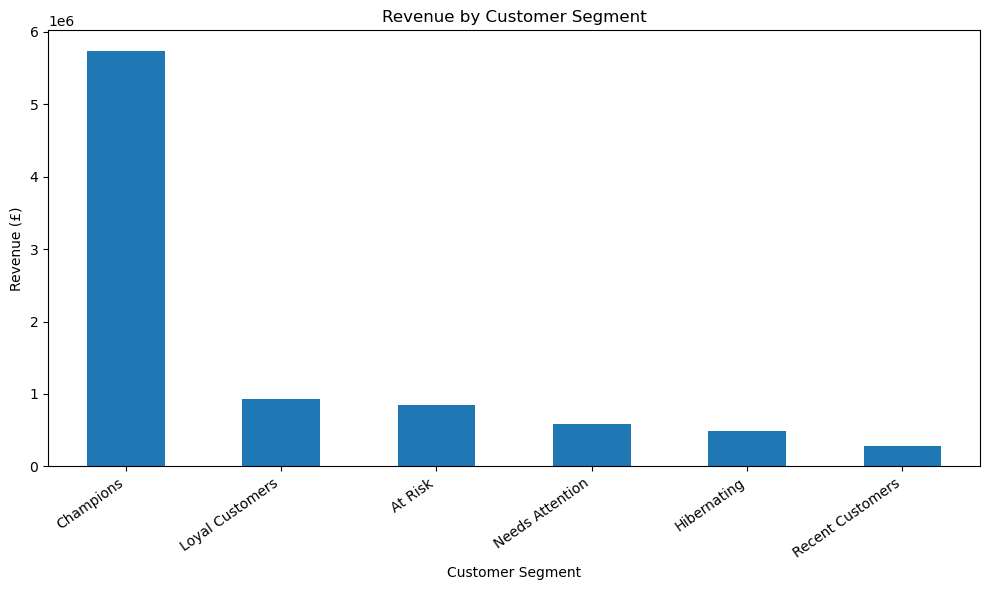

In [10]:
revenue_by_segment = (
    segments.groupby("customer_segment")["monetary"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
revenue_by_segment.plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig("revenue_by_segment.png", dpi=300, bbox_inches="tight")
plt.show()


In [11]:
total_customers = segments["customer_id"].nunique()
total_revenue = segments["monetary"].sum()

kpis = (
    segments.groupby("customer_segment")
    .agg(
        customers=("customer_id", "nunique"),
        revenue=("monetary", "sum")
    )
)

kpis["customer_share_pct"] = (
    kpis["customers"] / total_customers * 100
).round(2)

kpis["revenue_share_pct"] = (
    kpis["revenue"] / total_revenue * 100
).round(2)

kpis = kpis.sort_values("revenue", ascending=False)

display(kpis.round(2)) 

,customers,revenue,customer_share_pct,revenue_share_pct
customer_segment,,,,
Champions,947,5730402.80,21.83,64.48
Loyal Customers,487,936486.59,11.23,10.54
At Risk,670,849783.34,15.44,9.56
Needs Attention,856,587616.28,19.73,6.61
Hibernating,1066,495535.20,24.57,5.58
Recent Customers,312,287384.68,7.19,3.23
